# Photo Retouch — Refinement Experiments

Advanced Mathematics for Deep Learning final project.

This notebook continues `photo_retouch_training.ipynb`. That notebook keeps
every earlier experiment with its outputs and is no longer extended. Its
reusable code now lives in the `photo_retouch` package (`src/photo_retouch/`),
so this notebook imports functions instead of redefining them.

Nothing here retrains earlier models. They are loaded from `models/`, and every
evaluation uses the frozen validation snapshot in `records/`. The first
sections restore that state and check it against the saved records.

## Setup

Install the package in the notebook's environment once (see ENVIRONMENT.md):

```bash
python -m pip install --no-build-isolation --no-deps -e .
```

The install is editable: after changing a file in `src/photo_retouch/`, restart
the kernel to use the new code. No reinstall is needed.

| Module | Contents |
| --- | --- |
| `data` | Image loading, the validation set, mixed masks, training batches |
| `models` | Coarse U-Net loading, gated-conv refiner, patch discriminator, refine functions |
| `features` | Frozen VGG16 and InceptionV3 extractors |
| `losses` | Masked L1, perceptual, style, and hinge losses |
| `training` | Loss-weight calibration and the adversarial refiner update |
| `metrics` | Masked MAE, frequency errors, perceptual distance, KID, detail energy, grid test, paired comparisons |
| `plotting` | Side-by-side visual comparisons |

In [1]:
import pandas as pd
import tensorflow as tf

from photo_retouch.data import load_validation_set
from photo_retouch.device import configure_device
from photo_retouch.metrics import Evaluator
from photo_retouch.models import (
    COARSE_MODEL_FILE,
    SAVED_REFINERS,
    load_saved_model,
    predict_coarse,
    refine_images,
)
from photo_retouch.plotting import show_comparison
from photo_retouch.training import saved_loss_weights

TRAINING_DEVICE = configure_device()
print(f"TensorFlow: {tf.__version__}")
print(f"Preferred device: {TRAINING_DEVICE}")

TensorFlow: 2.18.1
Preferred device: /GPU:0


## Load the Frozen Validation Setup

Read the 400 validation images and their fixed mixed masks from the experiment
snapshot. Preprocessing matches training: decode, scale to [0, 1], and resize
to 128 × 128. The fixed visual examples are the highest-coverage image of each
category.

In [2]:
validation = load_validation_set()
examples = validation.example_indices()

print(f"Snapshot: {validation.record_dir.name}")
print(f"Validation images: {len(validation)}")
print(f"Mean hole coverage: {validation.masks.mean():.1%}")

Snapshot: 20261117T213223_080287Z
Validation images: 400
Mean hole coverage: 13.7%


## Reconstruct the Validation Set with the Saved Models

The frozen coarse U-Net fills each hole, and each refiner refines that coarse
result. `SAVED_REFINERS` pairs every saved refiner with the function it was
trained with. The low-chroma refiners must be applied with
`refine_low_chroma`; with `refine`, their colours are wrong.

In [3]:
COARSE_NAME = "Deep U-Net (MAE reference)"

coarse_model = load_saved_model(COARSE_MODEL_FILE)
reconstructions = {COARSE_NAME: predict_coarse(coarse_model, validation)}

for name, (filename, refine_fn) in SAVED_REFINERS.items():
    refiner = load_saved_model(filename)
    reconstructions[name] = refine_images(
        refiner, reconstructions[COARSE_NAME], validation.masks, refine_fn
    )
    print(f"{name:<22} {filename:<28} {refine_fn.__name__}")

L1 refiner             refiner_l1_control.keras     refine


Texture refiner        refiner_texture.keras        refine


Low-chroma refiner     refiner_low_chroma.keras     refine_low_chroma


Low-chroma, no style   refiner_no_style.keras       refine_low_chroma


## Check the Restored State Against the Saved Records

Recompute every metric with the package and compare it with the tables saved
by the earlier notebook:

- the metric summaries of the refinement experiment and its follow-up;
- the paired comparisons of the follow-up variants;
- the colour-fringing (detail energy) ratios;
- the grid-periodicity test.

If the values match, the data, models, and metric code were carried over
unchanged. Any difference stops the notebook here.

In [4]:
evaluator = Evaluator(validation)
evaluations = {
    name: evaluator.evaluate(results) for name, results in reconstructions.items()
}

PAIRS = [
    ("Low-chroma refiner", COARSE_NAME),
    ("Low-chroma refiner", "Texture refiner"),
    ("Low-chroma, no style", COARSE_NAME),
    ("Low-chroma, no style", "Texture refiner"),
    ("Low-chroma, no style", "Low-chroma refiner"),
]

recomputed = {
    "metric_summary": pd.DataFrame({
        name: evaluation.summary() for name, evaluation in evaluations.items()
    }).T,
    "paired_comparisons": pd.DataFrame([
        {"method": method, "baseline": baseline,
         **evaluator.paired(evaluations[method], evaluations[baseline])}
        for method, baseline in PAIRS
    ]).set_index(["method", "baseline"]),
    "detail_energy": pd.DataFrame({
        name: evaluator.detail_summary(results)
        for name, results in reconstructions.items()
    }).T,
    "grid_periodicity": pd.DataFrame([
        {"method": name, **row}
        for name, images in {
            "True image": validation.originals, **reconstructions
        }.items()
        for row in evaluator.grid_periodicity(images)
    ]).set_index(["method", "direction"]),
}

In [5]:
REFINE_DIR = validation.record_dir / "refinement"
FOLLOWUP_DIR = validation.record_dir / "refinement_followup"
TOLERANCE = 1e-6

saved = {
    "metric_summary": pd.concat([
        pd.read_csv(REFINE_DIR / "metric_summary.csv", index_col="method"),
        pd.read_csv(FOLLOWUP_DIR / "metric_summary.csv", index_col="method"),
    ]),
    "paired_comparisons": pd.read_csv(
        FOLLOWUP_DIR / "paired_comparisons.csv", index_col=["method", "baseline"]
    ),
    "detail_energy": pd.read_csv(
        FOLLOWUP_DIR / "detail_energy.csv", index_col="method"
    ),
    "grid_periodicity": pd.read_csv(
        FOLLOWUP_DIR / "grid_periodicity_variants.csv",
        index_col=["method", "direction"],
    ),
}


def compare_with_record(new_table, saved_table):
    # Methods saved in both experiments appear twice; keep the latest row.
    saved_table = saved_table[~saved_table.index.duplicated(keep="last")]
    shared = new_table.index.intersection(saved_table.index)
    new = new_table.loc[shared, saved_table.columns]
    old = saved_table.loc[shared]
    numeric = old.select_dtypes("number").columns
    text = old.columns.difference(numeric)
    return {
        "rows compared": len(shared),
        "max numeric difference": (
            new[numeric].astype(float) - old[numeric]
        ).abs().max().max(),
        "text cells differing": int((new[text].astype(str) != old[text]).sum().sum()),
    }


state_check = pd.DataFrame({
    table: compare_with_record(recomputed[table], saved[table])
    for table in saved
}).T.astype({"rows compared": int, "text cells differing": int})
display(state_check)

assert (state_check["max numeric difference"] < TOLERANCE).all()
assert (state_check["text cells differing"] == 0).all()
print("The restored state reproduces the saved records.")

,rows compared,max numeric difference,text cells differing
metric_summary,5,2.761307e-08,0
paired_comparisons,5,4.880524e-09,0
detail_energy,4,4.330139e-08,0
grid_periodicity,8,0.000000e+00,0


The restored state reproduces the saved records.


## Results So Far

Pixel error, perceptual distance, and KID (lower is better for all three),
with the fine-detail energy in luminance and chroma relative to the true
images (1 matches the truth). The paired comparisons give image-by-image
differences with 95% bootstrap intervals; negative values favour the method.

In [6]:
overview = recomputed["metric_summary"][
    ["masked_mae", "feature_distance", "kid_x1000"]
].join(recomputed["detail_energy"][["luma_detail_ratio", "chroma_detail_ratio"]])

with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(overview.round(4))
    display(recomputed["paired_comparisons"].round(4))

,masked_mae,feature_distance,kid_x1000,luma_detail_ratio,chroma_detail_ratio
Deep U-Net (MAE reference),0.0932,0.8803,4.7893,0.0292,0.2835
L1 refiner,0.0930,0.8758,4.6346,0.0279,0.2820
Texture refiner,0.1044,0.7057,-0.1895,0.6803,3.8364
Low-chroma refiner,0.1059,0.7083,0.0677,0.8070,1.0888
"Low-chroma, no style",0.0992,0.7229,0.4159,0.4707,0.7489


masked_mae Δ   masked_mae 95% CI masked_mae images better  feature_distance Δ feature_distance 95% CI feature_distance images better  KID×1000 Δ  \
method               baseline                                                                                                                                                                       
Low-chroma refiner   Deep U-Net (MAE reference)        0.0127  [+0.0117, +0.0136]                       6%             -0.1720      [-0.1875, -0.1572]                            93%     -4.7216   
                     Texture refiner                   0.0016  [+0.0012, +0.0020]                      36%              0.0027      [-0.0025, +0.0081]                            49%      0.2571   
Low-chroma, no style Deep U-Net (MAE reference)        0.0059  [+0.0053, +0.0065]                      11%             -0.1574      [-0.1704, -0.1450]                            96%     -4.3734   
                     Texture refiner                  -0.0052  [-0.0057, -0.0048]                      91%              0.0173      [+0.0101, +0.0243]                            42%      0.6053   
                     Low-chroma refiner               -0.0068  [-0.0073, -0.0063]                      95%              0.0146      [+0.0073, +0.0215]                            47%      0.3482   

                                                KID subsets lower  
method               baseline                                      
Low-chroma refiner   Deep U-Net (MAE reference)              100%  
                     Texture refiner                          16%  
Low-chroma, no style Deep U-Net (MAE reference)              100%  
                     Texture refiner                           9%  
                     Low-chroma refiner                       20%

## Visual Check

The coarse fill, the texture refiner, and both follow-up variants on the
fixed examples.

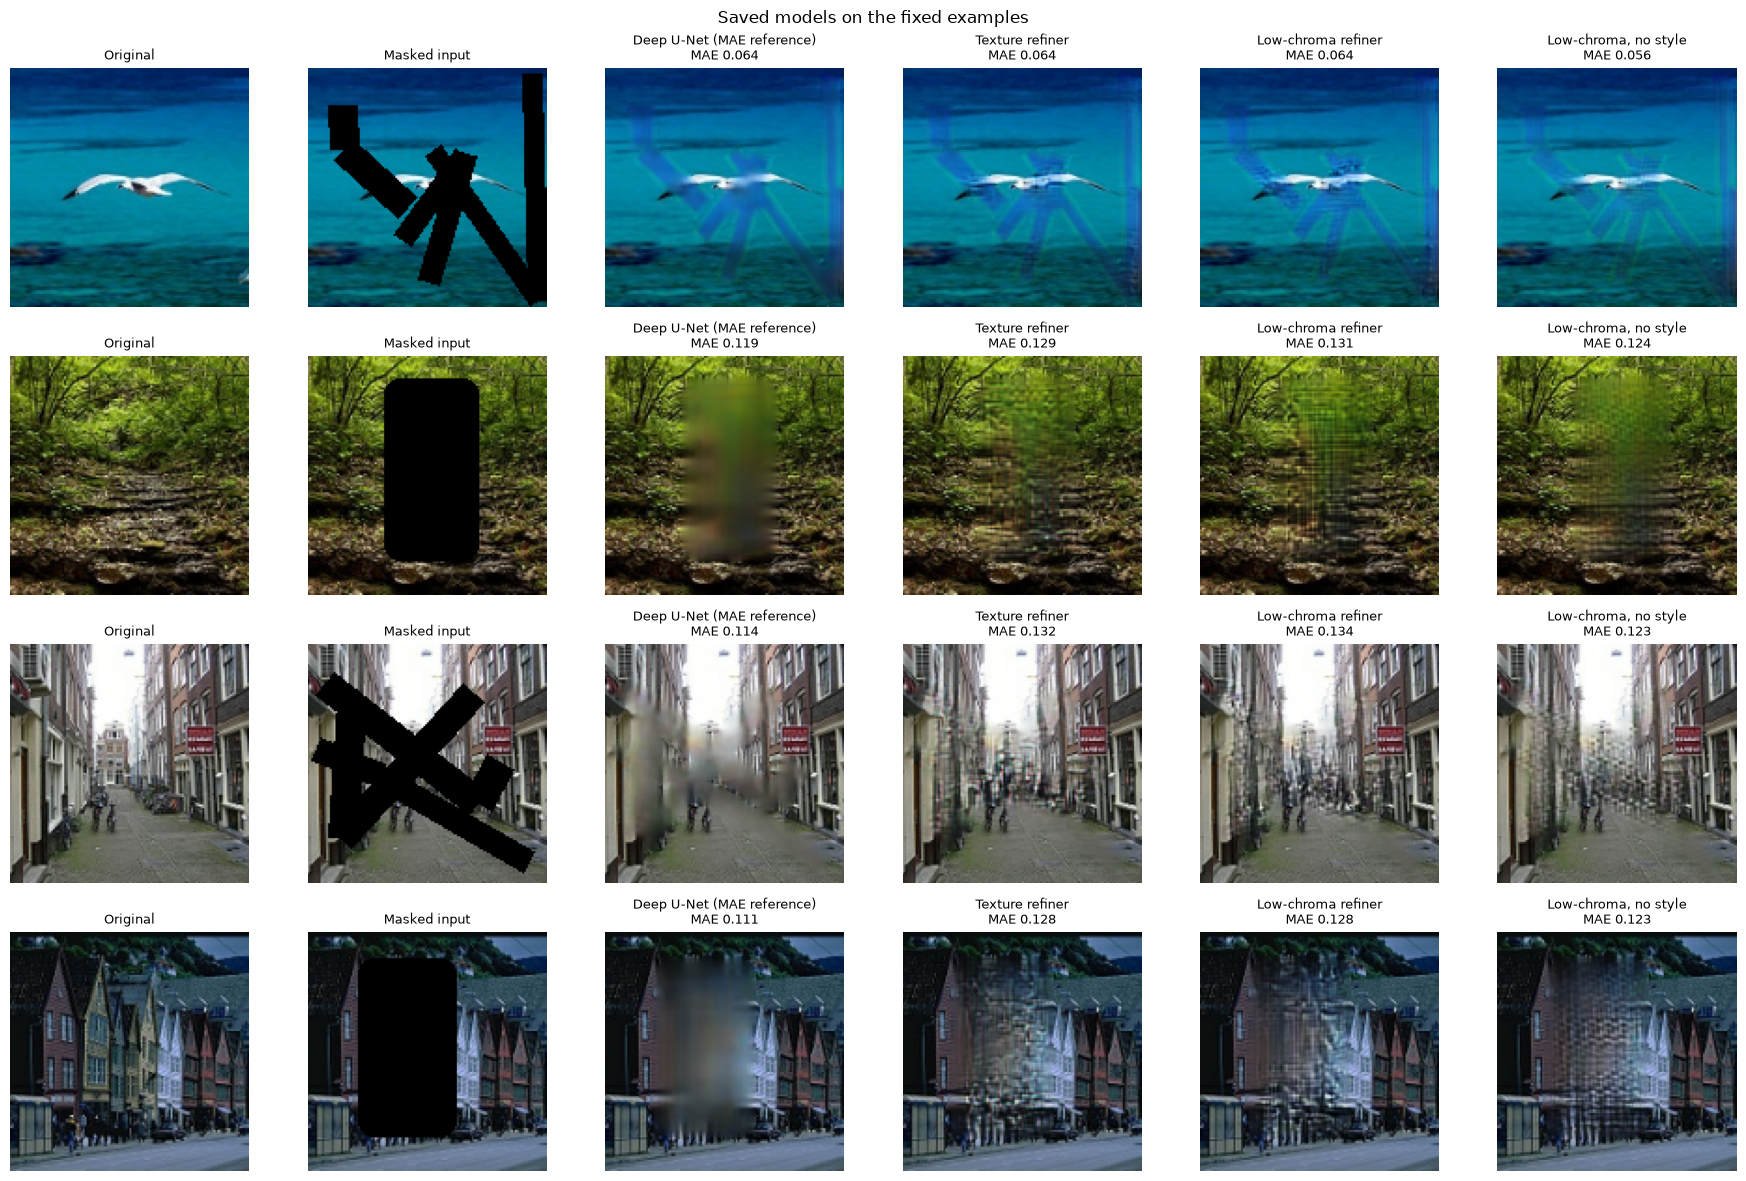

In [7]:
show_comparison(
    validation,
    {
        name: reconstructions[name]
        for name in [
            COARSE_NAME, "Texture refiner",
            "Low-chroma refiner", "Low-chroma, no style",
        ]
    },
    examples,
    "Saved models on the fixed examples",
)

## Training Settings Carried Over

The refiners were trained with loss weights calibrated so that the perceptual
and style gradients initially match the masked-L1 gradient, and with an
adaptive adversarial weight at half the reconstruction gradient. The values
are stored in the refinement checkpoint. `photo_retouch.training` also
provides the same training batches (`TrainingBatches`), the calibration
(`calibrate_loss_weights`), and the adversarial update (`new_arm`,
`make_train_step`) for new variants.

In [8]:
PERCEPTUAL_WEIGHT, STYLE_WEIGHT, ADV_RATIO = saved_loss_weights()

print(f"Perceptual weight: {PERCEPTUAL_WEIGHT:.4g}")
print(f"Style weight: {STYLE_WEIGHT:.4g}")
print(f"Adversarial ratio: {ADV_RATIO:g}")

Perceptual weight: 0.0002139
Style weight: 8.88e-05
Adversarial ratio: 0.5


## Starting Point

**Best candidate: the low-chroma refiner.** Compared with the coarse U-Net, it
lowers perceptual distance from 0.880 to 0.708 and KID × 1000 from 4.79 to
0.07, at a cost of 0.013 in masked MAE. It removes the texture refiner's
colour fringing (chroma detail 1.09 times the truth instead of 3.84) with no
measurable loss in perceptual distance.

**Open problem: a blocky luminance mosaic on facades.** Removing the style
loss made it worse, as Liu et al. (2018) report for perceptual losses without
a style term. Two causes remain untested:

1. **Style weight too small.** Liu et al. observe "fish scale" artifacts when
   the style weight is small. Ours was set by a gradient-norm heuristic, and
   its relative weight is much lower than theirs.
2. **Nearest-neighbour upsampling.** The low-chroma refiner has a 4-px grid
   component about twice that of the true images. That period matches the
   decoder's two ×2 nearest-neighbour upsampling layers.

**Human judgement is still missing.** The blind-review pages in `records/`
were generated before the refiners existed. A new panel that includes the
low-chroma refiner is needed to check whether the measured gain outweighs
the visible artifacts.

Each refiner variant is a single training run, so small differences may
reflect initialization rather than the change being tested.